# KYC: Bayes, evidencia duplicada y calibración

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Posterior correcto:** 0.2081
- **Posterior inválido por duplicación:** 0.7293
- **Positivos de prueba:** 26
- **Error máximo de gradiente:** 1.6550684434069105e-12
- **Posterior con copia total:** 0.2081

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Cuánto cambia una probabilidad de fraude con una señal y qué error aparece al contar la misma evidencia dos veces? Derivamos Bayes, construimos un contraejemplo exacto y comparamos logit con calibración posterior.

### Supuestos y población

Una señal binaria tiene sensibilidad y falso positivo conocidos por el simulador. Los bloques de entrenamiento, calibración y prueba se ordenan por índice; su mecanismo es estacionario y las etiquetas están completas.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. De prevalencia a probabilidad posterior


Sea $Y=1$ fraude y $E=1$ evidencia positiva. Con prevalencia $\pi$, sensibilidad $s$ y falso positivo $f$:

$$P(Y=1\mid E=1)=\frac{\pi s}{\pi s+(1-\pi)f}.$$

En odds, $O(Y\mid E)=O(Y)LR(E)$ y $LR(E=1)=s/f$. Una señal informativa puede tener precisión baja si la prevalencia es pequeña. No reemplazar $P(Y\mid E)$ por $P(E\mid Y)$.

,prevalencia,sensibilidad,falso_positivo,posterior_positivo
0,0.0250,0.8200,0.0800,0.2081


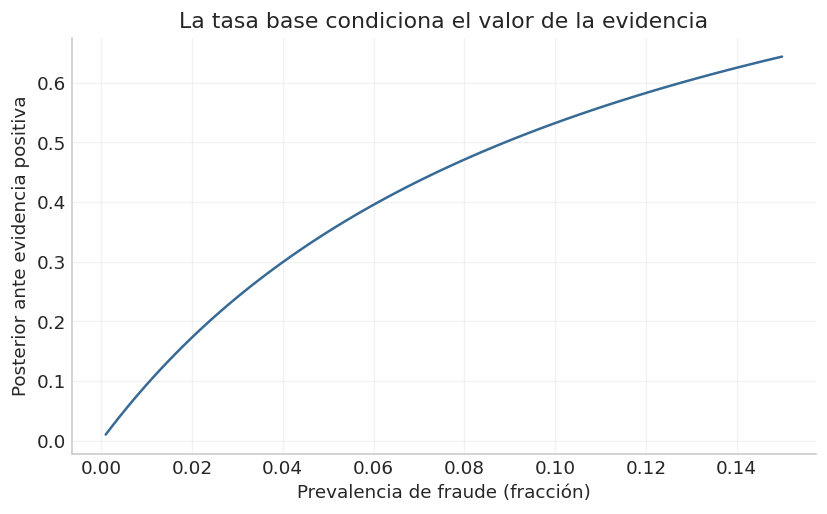

In [2]:
prevalence, sensitivity, false_positive = .025, .82, .08
posterior = prevalence*sensitivity/(prevalence*sensitivity+(1-prevalence)*false_positive)
prior_grid = np.linspace(.001,.15,100)
posterior_grid = prior_grid*sensitivity/(prior_grid*sensitivity+(1-prior_grid)*false_positive)
display(pd.DataFrame({'prevalencia':[prevalence], 'sensibilidad':[sensitivity], 'falso_positivo':[false_positive], 'posterior_positivo':[posterior]}))
fig,ax=plt.subplots();ax.plot(prior_grid,posterior_grid,color=BLUE)
ax.set(xlabel='Prevalencia de fraude (fracción)',ylabel='Posterior ante evidencia positiva',title='La tasa base condiciona el valor de la evidencia')
plt.show()

La curva mantiene fija la calidad de la señal. Cambiar la prevalencia no convierte una misma verificación en una prueba concluyente. Las probabilidades provienen del supuesto conocido, no de una fuente KYC real.

## 2. Contraejemplo: dos campos, una sola evidencia


Si $E_2=E_1$, la información conjunta es la misma. La identidad correcta es
$P(Y\mid E_1,E_2)=P(Y\mid E_1)$. Bajo una independencia falsa se multiplicaría $LR^2$ y se exageraría la confianza.

,método,probabilidad
0,Una evidencia / duplicación correcta,0.2081
1,Duplicación con independencia falsa,0.7293


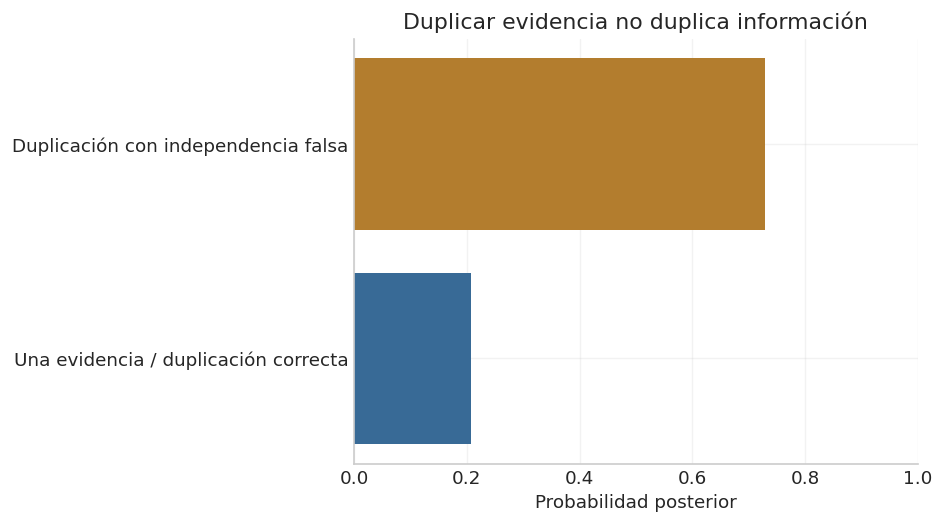

In [3]:
prior_odds=prevalence/(1-prevalence)
likelihood_ratio=sensitivity/false_positive
naive_odds=prior_odds*likelihood_ratio**2
naive_probability=naive_odds/(1+naive_odds)
comparison=pd.DataFrame({'método':['Una evidencia / duplicación correcta','Duplicación con independencia falsa'],
                         'probabilidad':[posterior,naive_probability]})
display(comparison)
fig,ax=plt.subplots();ax.barh(comparison['método'],comparison['probabilidad'],color=[BLUE,GOLD])
ax.set(xlim=(0,1),xlabel='Probabilidad posterior',title='Duplicar evidencia no duplica información');fig.tight_layout();plt.show()

El segundo cálculo es deliberadamente inválido. Dos proveedores que copian el mismo origen no generan automáticamente dos confirmaciones independientes. La trazabilidad de origen importa tanto como el número de campos.

## 3. Estimación y calibración en ventanas separadas


Un logit estima $\hat p=\sigma(\beta_0+\beta^Tx)$ mediante log loss. Un calibrador posterior estima $\tilde p=\sigma(a+b\,\mathrm{logit}(\hat p))$. Las muestras para ambos ajustes son distintas. Brier es $n^{-1}\sum_i(\hat p_i-y_i)^2$.

In [4]:
from sklearn.linear_model import LogisticRegression
n=4000
y=rng.binomial(1,prevalence,n)
e1=rng.binomial(1,np.where(y==1,sensitivity,false_positive))
e2=e1.copy()
x=np.column_stack([e1,e2,rng.normal(size=n)])
train,cal,test=np.arange(2000),np.arange(2000,3000),np.arange(3000,4000)
model=LogisticRegression(C=1,max_iter=500).fit(x[train],y[train])
weighted=LogisticRegression(C=1,class_weight='balanced',max_iter=500).fit(x[train],y[train])
calibrator=LogisticRegression(C=100,max_iter=500).fit(weighted.decision_function(x[cal]).reshape(-1,1),y[cal])
predictions={'logit':model.predict_proba(x[test])[:,1],
             'logit balanceado sin calibrar':weighted.predict_proba(x[test])[:,1],
             'balanceado y calibrado':calibrator.predict_proba(weighted.decision_function(x[test]).reshape(-1,1))[:,1]}
score_table=pd.DataFrame([{'modelo':k,'AP':average_precision_score(y[test],v),'Brier':brier_score_loss(y[test],v),'media_p':v.mean()} for k,v in predictions.items()])
display(score_table)
print('Prevalencia de prueba:',y[test].mean(),'positivos:',y[test].sum())

Prevalencia de prueba: 0.026 positivos: 26


,modelo,AP,Brier,media_p
0,logit,0.2000,0.0221,0.0314
1,logit balanceado sin calibrar,0.2000,0.0974,0.2492
2,balanceado y calibrado,0.2000,0.0224,0.0170


Balancear clases cambia el ajuste y puede alterar la escala probabilística. La tabla permite comprobarlo sin asumir que calibrar siempre mejora. Con pocos positivos, otra semilla o ventana puede modificar el resultado; este notebook no elige hiperparámetros por el test.

## Desarrollo ampliado: modelo, estimación y uso


**Uso:** priorizar comprobaciones KYC cuando varias fuentes discrepan. **Unidad:** solicitud al cierre de una etapa. **Entrada:** indicadores de contradicción y disponibilidad; **salida:** probabilidad calibrada, nunca identidad certificada. Se separan tres objetos: calidad de evidencia, probabilidad de fraude y decisión económica.

El modelo logit supone log odds aditivas; una interacción requiere un término explícito. La estimación minimiza log loss regularizada. Las etiquetas deben representar adjudicación y estar disponibles en el corte de ajuste. Aquí son completas por construcción. Una auditoría institucional debe analizar también clientes sin etiqueta, cambios de proveedor y población rechazada.

In [5]:
advanced_metrics = {}
advanced_rng = np.random.default_rng(9221)

### 4. Derivar log loss, gradiente y curvatura


Con $z_i=\beta_0+x_i^T\beta$ y $p_i=\sigma(z_i)$, la log-verosimilitud Bernoulli es $\sum_i[y_i z_i-\log(1+e^{z_i})]$. Minimizar su negativo medio más penalización da:

$$J(\theta)=\frac1n\sum_i[\log(1+e^{z_i})-y_i z_i]+\frac\lambda2\|\beta\|^2,$$
$$\nabla J=\frac1n X_*^T(p-y)+\lambda D\theta,\qquad H=\frac1n X_*^TWX_*+\lambda D.$$

$X_*$ añade intercepto; $D=\operatorname{diag}(0,1,\ldots,1)$ evita penalizarlo y $W_{ii}=p_i(1-p_i)$. Esta convención de lambda no se identifica sin más con C de una librería. `logaddexp` evita desbordamiento.

In [6]:
from scipy.special import expit
from scipy.optimize import minimize
X_star=np.column_stack([np.ones(len(train)),x[train]])
D=np.diag([0.,1.,1.,1.]);penalty=.02
def logistic_objective(theta):
    z=X_star@theta;p_hat=expit(z)
    value=np.mean(np.logaddexp(0,z)-y[train]*z)+penalty/2*(theta@D@theta)
    gradient=X_star.T@(p_hat-y[train])/len(train)+penalty*D@theta
    return value,gradient
fit=minimize(logistic_objective,np.zeros(4),jac=True,method='BFGS',options={'gtol':1e-8})
theta=fit.x
step=1e-5
finite_gradient=np.array([(logistic_objective(theta+np.eye(4)[j]*step)[0]-logistic_objective(theta-np.eye(4)[j]*step)[0])/(2*step) for j in range(4)])
analytic_gradient=logistic_objective(theta)[1]
fit_p=expit(X_star@theta)
hessian=(X_star.T*(fit_p*(1-fit_p)))@X_star/len(train)+penalty*D
display(pd.DataFrame({'parámetro':['intercepto','E1','E2','ruido'],'coeficiente':theta,'gradiente':analytic_gradient,'diferencia_finita':finite_gradient}))
assert np.linalg.norm(analytic_gradient,ord=np.inf)<1e-6
assert np.max(np.abs(finite_gradient-analytic_gradient))<1e-6
assert np.linalg.eigvalsh(hessian).min()>-1e-10

,parámetro,coeficiente,gradiente,diferencia_finita
0,intercepto,-3.6977,0.0000,0.0000
1,E1,0.7626,0.0000,0.0000
2,E2,0.7626,0.0000,0.0000
3,ruido,-0.0701,0.0000,0.0000


**Interpretación y uso.** La derivación concilia con diferencias finitas y una curvatura no negativa. Los dos indicadores duplicados no son efectos causales independientes. La penalización estabiliza coeficientes, pero no valida las fuentes ni corrige sesgo de adjudicación.

### 5. Dependencia parcial entre evidencias


Supongamos que una segunda señal copia la primera con probabilidad $r$ y, de lo contrario, se genera independientemente condicionada a Y. Entonces
$$P(E_1=E_2=1\mid Y=1)=rs+(1-r)s^2,$$
$$P(E_1=E_2=1\mid Y=0)=rf+(1-r)f^2.$$
$r$ es probabilidad de copia, no coeficiente de correlación. Bayes debe usar estas probabilidades conjuntas, no un producto de marginales impuesto.

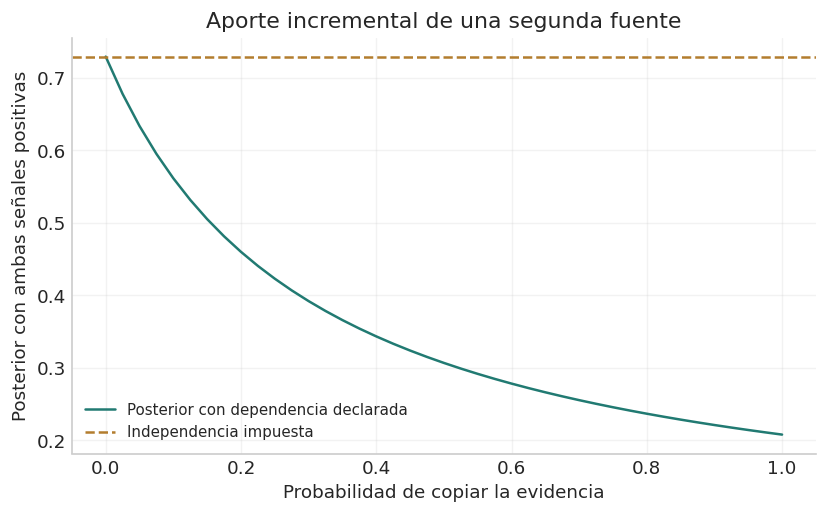

In [7]:
copy_grid=np.linspace(0,1,41)
true_joint=prevalence*(copy_grid*sensitivity+(1-copy_grid)*sensitivity**2)
false_joint=(1-prevalence)*(copy_grid*false_positive+(1-copy_grid)*false_positive**2)
correct_joint=true_joint/(true_joint+false_joint)
fig,ax=plt.subplots();ax.plot(copy_grid,correct_joint,color=TEAL,label='Posterior con dependencia declarada')
ax.axhline(naive_probability,color=GOLD,linestyle='--',label='Independencia impuesta')
ax.set(xlabel='Probabilidad de copiar la evidencia',ylabel='Posterior con ambas señales positivas',title='Aporte incremental de una segunda fuente');ax.legend(fontsize=9);plt.show()
assert np.isclose(correct_joint[0],naive_probability)
assert np.isclose(correct_joint[-1],posterior)

**Interpretación y uso.** Una fuente puede aportar menos a medida que aumenta su dependencia. Antes de añadir un proveedor, preguntar cuál es su origen informativo y si hay una validación externa o solo una réplica.

### 6. Confiabilidad y tamaño de muestra


Para un grupo B de predicciones, comparar $\bar p_B$ con $\bar y_B$. Una discrepancia es un diagnóstico de calibración, no una prueba concluyente con pocos casos. Se usan cinco bins por cuantiles de score y se publica n por bin.

,modelo,bin,n,predicho,observado
0,logit,0,200,0.0062,0.0050
1,logit,1,200,0.0074,0.0050
2,logit,2,200,0.0083,0.0000
3,logit,3,200,0.0095,0.0150
4,logit,4,200,0.1257,0.1050
5,logit balanceado sin calibrar,0,200,0.1376,0.0050
6,logit balanceado sin calibrar,1,200,0.1621,0.0050
7,logit balanceado sin calibrar,2,200,0.1804,0.0000
8,logit balanceado sin calibrar,3,200,0.2022,0.0150
9,logit balanceado sin calibrar,4,200,0.5634,0.1050


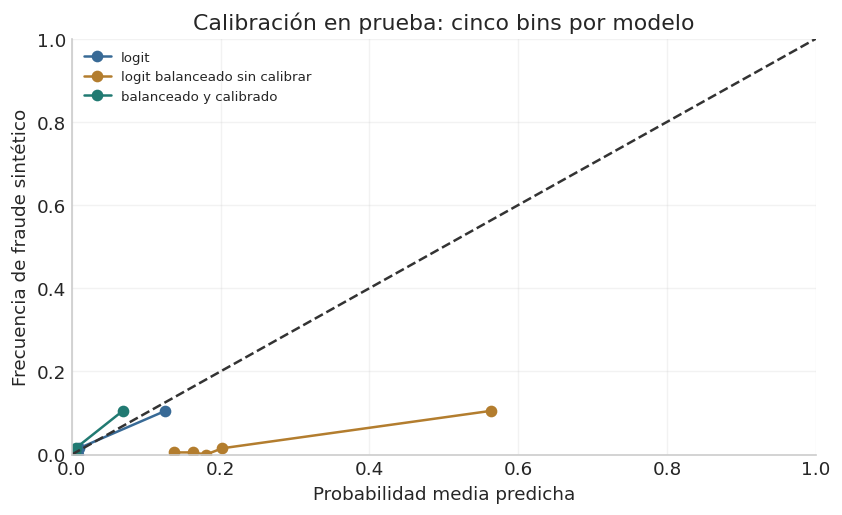

In [8]:
calibration_rows=[]
for name,p_values in predictions.items():
    bins=pd.qcut(pd.Series(p_values),5,labels=False,duplicates='drop')
    for b in sorted(bins.dropna().unique()):
        mask=(bins.to_numpy()==b)
        calibration_rows.append({'modelo':name,'bin':int(b),'n':int(mask.sum()),'predicho':float(p_values[mask].mean()),'observado':float(y[test][mask].mean())})
reliability=pd.DataFrame(calibration_rows)
display(reliability.round(4))
fig,ax=plt.subplots()
for name,color in zip(predictions,[BLUE,GOLD,TEAL]):
    subset=reliability[reliability['modelo']==name]
    ax.plot(subset['predicho'],subset['observado'],marker='o',label=name,color=color)
ax.plot([0,1],[0,1],linestyle='--',color='#333333');ax.set(xlim=(0,1),ylim=(0,1),xlabel='Probabilidad media predicha',ylabel='Frecuencia de fraude sintético',title='Calibración en prueba: cinco bins por modelo');ax.legend(fontsize=8);plt.show()

**Interpretación y uso.** Dos modelos pueden ordenar igual y tener costos distintos por mala escala probabilística. Las frecuencias de este test tienen solo 26 positivos; no se presentan como curvas poblacionales exactas.

### 7. Cambio de tasa base y actualización de odds


Si solo cambia $\pi$ y se conservan las distribuciones de evidencia condicionadas a Y, las odds se ajustan por
$$O_{new}(Y\mid E)=O_{old}(Y\mid E)\frac{\pi_{new}/(1-\pi_{new})}{\pi_{old}/(1-\pi_{old})}.$$
Es una hipótesis de cambio de prior, no una solución universal a drift. Si el atacante cambia el mecanismo de evidencia, no basta ajustar la tasa base.

In [9]:
new_prior=.10
new_y=advanced_rng.binomial(1,new_prior,5000)
new_e=advanced_rng.binomial(1,np.where(new_y==1,sensitivity,false_positive))
def exact_posterior(prior,e):
    positive=prior*sensitivity/(prior*sensitivity+(1-prior)*false_positive)
    negative=prior*(1-sensitivity)/(prior*(1-sensitivity)+(1-prior)*(1-false_positive))
    return np.where(e==1,positive,negative)
old_prob=exact_posterior(prevalence,new_e)
old_odds=old_prob/(1-old_prob)
ratio=(new_prior/(1-new_prior))/(prevalence/(1-prevalence))
adjusted=old_odds*ratio/(1+old_odds*ratio)
reference=exact_posterior(new_prior,new_e)
display(pd.DataFrame({'escala':['Prior antiguo','Ajuste de odds'],'Brier':[brier_score_loss(new_y,old_prob),brier_score_loss(new_y,adjusted)],'media_p':[old_prob.mean(),adjusted.mean()]}))
assert np.allclose(adjusted,reference)
advanced_metrics.update({'Error máximo de gradiente':float(np.max(np.abs(finite_gradient-analytic_gradient))),'Posterior con copia total':round(float(correct_joint[-1]),4)})

,escala,Brier,media_p
0,Prior antiguo,0.0717,0.0358
1,Ajuste de odds,0.0536,0.0988


**Interpretación y uso.** La igualdad con Bayes es una comprobación analítica bajo un supuesto controlado. La prevalencia futura no estaría conocida en una aplicación: debe estimarse con etiquetas maduras y la incertidumbre debe conservarse.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [10]:
assert posterior < naive_probability < 1
assert np.array_equal(e1,e2)
assert all(np.isfinite(v).all() and ((v>=0)&(v<=1)).all() for v in predictions.values())

## Resultados computados

In [11]:
metrics = {'Posterior correcto': round(posterior,4), 'Posterior inválido por duplicación': round(naive_probability,4), 'Positivos de prueba': int(y[test].sum())}
metrics.update(advanced_metrics)
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Posterior correcto": 0.2081, "Posterior inválido por duplicación": 0.7293, "Positivos de prueba": 26, "Error máximo de gradiente": 1.6550684434069105e-12, "Posterior con copia total": 0.2081}


## Ideas y preguntas para continuar

1. Estimar dependencia entre fuentes y conservar el origen de cada campo.
2. Comparar calibración por proveedor con contracción jerárquica cuando haya pocos positivos.
3. Evaluar degradación al cambiar prevalencia sin cambiar sensibilidad.
4. Investigar reglas de abstención cuando faltan fuentes; faltante no significa legítimo.

## Fuentes y relación con el proyecto

- [Calibración: documentación oficial scikit-learn](https://scikit-learn.org/stable/modules/calibration.html).
- [NIST: identidad y gestión de evidencia](https://pages.nist.gov/800-63-4/sp800-63a.html).
Las derivaciones de Bayes y el contraejemplo se calculan directamente en estas celdas.

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.

## Uso responsable y ficha mínima de salida

Antes de una aplicación institucional, registrar población, corte de información, versión del modelo, horizonte, unidades y cobertura de fuentes. Separar score de anomalía, probabilidad estimada y costo por acción. Una discrepancia o un desvío requiere evidencia independiente antes de llamarlo fraude. El experimento está completo en su alcance sintético; no sustituye calibración externa, integración de datos o validación independiente.

## Preguntas para refutar el desarrollo

1. ¿La mejora persiste al cambiar el mecanismo generador y la cohorte?
2. ¿Qué variable solo estaría disponible después de decidir?
3. ¿Cuánto del beneficio depende de una eficacia o cobertura supuesta?
4. ¿Qué caso legítimo produce la misma señal?
5. ¿Puede otra persona reconstruir el resultado desde las celdas y los parámetros?

## Diccionario de símbolos y unidades

| Símbolo | Significado en este notebook | Unidad o restricción |
|---|---|---|
| p, π | Probabilidad posterior y tasa base | Fracción entre 0 y 1 |
| s, f | Sensibilidad y falso positivo de la evidencia | Fracción; no son fricción monetaria |
| r | Probabilidad de que una fuente copie otra | Fracción, no correlación |
| β, θ | Coeficientes y vector con intercepto | Log odds por unidad de entrada |
| λ, D | Penalización y máscara sin intercepto | Convención del objetivo explícita |
| H, W | Hessiano y pesos p(1−p) | Curvatura del objetivo |

## Modelos y casos de uso

| Modelo o técnica | Para qué usarlo | Condición para interpretar su salida |
|---|---|---|
| Bayes conjunto | Actualizar evidencia y evitar doble conteo | Requiere origen y dependencia de fuentes |
| Logit regularizado | Ranking probabilístico interpretable | Validar escala y etiqueta adjudicada |
| Calibrador sigmoidal | Corregir escala de un modelo congelado | Ventana posterior; no tuning en test |
| Ajuste de odds | Analizar un cambio de tasa base | Solo si el mecanismo condicionado a Y permanece |

Referencias técnicas adicionales: [logit](https://scikit-learn.org/stable/modules/linear_model.html), [beta-binomial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.betabinom.html), [MILP](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html). Las distribuciones, datos y resultados de este notebook son sintéticos y se generan en las celdas.